# 07 · Form, "who did they beat?", and fight chains

**The idea.** When A fights B, look past the records:
- **How** has each fighter been winning lately: knockouts, submissions, or on the cards?
- **Who** did they beat, and what shape were *those* opponents in? Say B's last opponent was on a 5-fight win streak and B still beat him. That should mean something.
- Go one level deeper: what did the opponents' opponents do? And did A and B ever face the same people?

Does any of this tell us **who** wins, and **how**? We first *explore* it (simple win rates), then *test* it the honest way: does it improve predictions on fights the model has never seen?

All features are built in `src/ufc/form.py` from fights **strictly before** the one being predicted.

## 1 · Four layers of "what happened before tonight"
| Layer | Features | Idea |
|---|---|---|
| **1. Own lead-up** | last-5 wins by KO / SUB / DEC, last-5 losses by method, finish streak, decision streak, recency-weighted form | *How* has the fighter been winning lately? |
| **2. Who they beat** | longest win streak they snapped, the streak their last opponent was on, average Elo of the opponents they beat / lost to, opponents' recent form | Beating someone on a 5-fight streak > beating someone on a 3-fight skid |
| **3. Strength of schedule** | **OWP** = past opponents' win rate (as of tonight); **OOWP** = those opponents' opponents' win rate | The "RPI" idea used to rank college teams |
| **4. Fight chains** | shared past opponents, "A beat C and C beat B" chains, previous meetings | "MMA math" |

One thing to keep in mind: **Elo** (notebook 05) already does a version of layers 2–3. Beating a highly rated opponent raises your rating more, and their rating already reflects who *they* beat.
So the real question is whether these features add anything **beyond** Elo and the career stats.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

from ufc import form as F, modeling as M
from ufc.features import MIN_FEATURES, HIST_FEATURES, swap_corners
from ufc.viz import use_style, SERIES, INK_2, NEUTRAL, GRID, METHOD_COLORS
from sklearn.metrics import log_loss, accuracy_score
use_style()

t, ff = M.load_model_table()                       # unshrunk version first
hist = pd.read_parquet("data/processed/elo_history.parquet")
assert F.check_no_lookahead_form(ff, hist, ff[F.KEY + F.ALL_NEW])   # brute-force spot check
print(f"{len(t):,} fights since 2010-03 (clean corners) · train < {M.SPLIT:%Y-%m-%d} ≤ test")

7,502 fights since 2010-03 (clean corners) · train < 2024-01-01 ≤ test


**Spot check:** one real fight, built by hand. Below is each fighter's last 5 fights, with the win streak each *opponent* was on going in. Compare it with the computed features.

In [2]:
SPOT = t[(t.date >= M.SPLIT) & (t.r_n_fights >= 6) & (t.b_n_fights >= 6)].sort_values("date").iloc[-40]
win_streak = ff.set_index(F.KEY).win_streak
def lead_up(name, before, n=5):
    p = ff[(ff.fighter == name) & (ff.date < before)].sort_values("date").tail(n)
    return pd.DataFrame({"date": p.date.dt.date.values, "opponent": p.opponent.values, "result": p.result.values,
                         "method": p.method_group.values,
                         "opponent's win streak going in": [win_streak.get((f, o)) for f, o in zip(p.fight_id, p.opponent)]})
print(f"{SPOT.r_fighter} vs {SPOT.b_fighter} · {SPOT.date:%Y-%m-%d} · winner: {SPOT.winner}")
for side, name in [("r_", SPOT.r_fighter), ("b_", SPOT.b_fighter)]:
    print(f"\n{name}"); display(lead_up(name, SPOT.date))
    print({f: SPOT[side + f] for f in ["l5_ko_w", "l5_sub_w", "l5_dec_w", "finish_streak", "beat_streak_max", "last_opp_streak", "owp"]})

Islam Makhachev vs Ian Machado Garry · 2026-08-15 · winner: Red

Islam Makhachev


,date,opponent,result,method,opponent's win streak going in
0,2023-02-11,Alexander Volkanovski,W,DEC,12
1,2023-10-21,Alexander Volkanovski,W,KO/TKO,1
2,2024-06-01,Dustin Poirier,W,SUB,1
3,2025-01-18,Renato Moicano,W,SUB,4
4,2025-11-15,Jack Della Maddalena,W,DEC,8


{'l5_ko_w': np.float64(1.0), 'l5_sub_w': np.float64(2.0), 'l5_dec_w': np.float64(2.0), 'finish_streak': np.float64(0.0), 'beat_streak_max': np.float64(12.0), 'last_opp_streak': np.float64(8.0), 'owp': np.float64(0.6202432374475385)}

Ian Machado Garry


,date,opponent,result,method,opponent's win streak going in
0,2024-02-17,Geoff Neal,W,DEC,0
1,2024-06-29,Michael Page,W,DEC,1
2,2024-12-07,Shavkat Rakhmonov,L,DEC,6
3,2025-04-26,Carlos Prates,W,DEC,4
4,2025-11-22,Belal Muhammad,W,DEC,0


{'l5_ko_w': np.float64(0.0), 'l5_sub_w': np.float64(0.0), 'l5_dec_w': np.float64(4.0), 'finish_streak': np.float64(0.0), 'beat_streak_max': np.float64(4.0), 'last_opp_streak': np.float64(0.0), 'owp': np.float64(0.5746803769531043)}


## 2 · Explore first: simple win rates
Each fight is viewed from **both** sides: fighter A vs fighter B, then B vs A. So every rate below is "how often a fighter in this situation won".
These are raw rates, with nothing held constant. A fighter on a 5-fight streak is usually also higher rated, younger and in better form, so these show *association*, not cause.
Section 4 tests what survives once everything is in the model together.

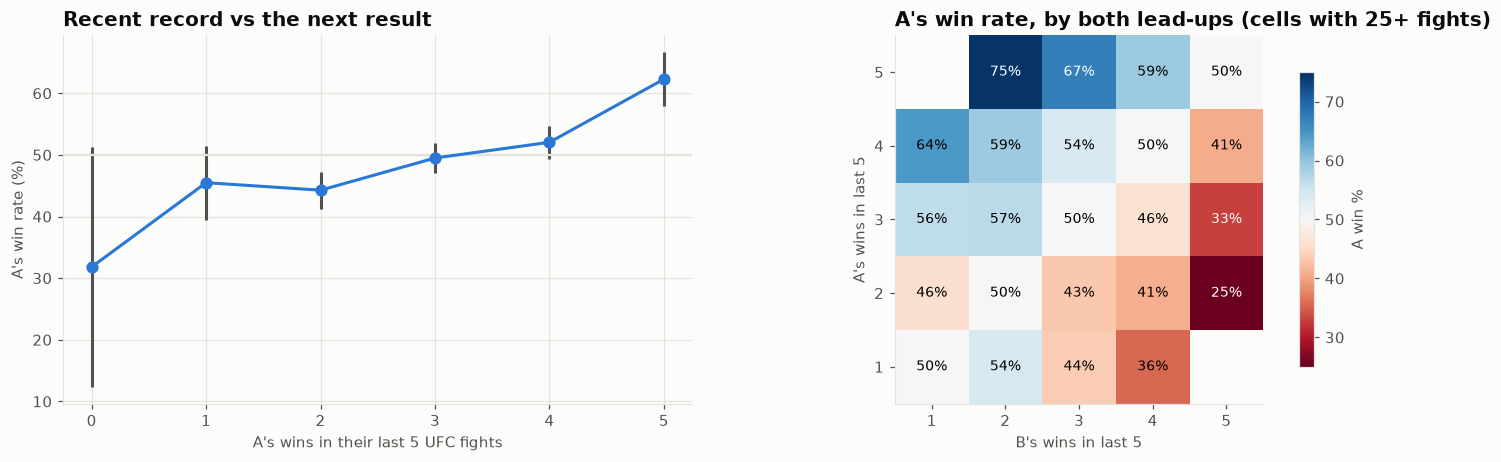

A_l5_wins,0,1,2,3,4,5
win_rate,0.318,0.455,0.443,0.495,0.520,0.623
n,22.000,266.000,1039.000,1681.000,1322.000,464.000
lo,0.124,0.395,0.413,0.471,0.493,0.579
hi,0.513,0.515,0.473,0.519,0.547,0.667


In [3]:
A = M.augment(t)            # r_ = fighter A, b_ = fighter B, red_win = "A won"
A = A.assign(won=A.red_win)

def rate_table(df, by):
    g = df.groupby(by, observed=True).won
    out = pd.DataFrame({"win_rate": g.mean(), "n": g.size()})
    se = np.sqrt(out.win_rate * (1 - out.win_rate) / out.n)
    return out.assign(lo=out.win_rate - 1.96 * se, hi=out.win_rate + 1.96 * se)

five = A[(A.r_l5_fights == 5) & (A.b_l5_fights == 5)].copy()
five["A_l5_wins"] = (five.r_l5_win_rate * 5).round().astype(int)
five["B_l5_wins"] = (five.b_l5_win_rate * 5).round().astype(int)
r1 = rate_table(five, "A_l5_wins")
heat = five.pivot_table(index="A_l5_wins", columns="B_l5_wins", values="won", aggfunc="mean")
cnt = five.pivot_table(index="A_l5_wins", columns="B_l5_wins", values="won", aggfunc="size")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
ax.errorbar(r1.index, r1.win_rate * 100, yerr=[(r1.win_rate - r1.lo) * 100, (r1.hi - r1.win_rate) * 100],
            fmt="o-", color=SERIES[0], ecolor=INK_2, capsize=0, ms=7)
ax.axhline(50, color=GRID, lw=1.5)
ax.set_xlabel("A's wins in their last 5 UFC fights"); ax.set_ylabel("A's win rate (%)")
ax.set_title("Recent record vs the next result")
ax = axes[1]
show = heat.where(cnt >= 25).dropna(how="all").dropna(axis=1, how="all")
im = ax.imshow(show.values * 100, cmap="RdBu", vmin=25, vmax=75, origin="lower")
for i in range(show.shape[0]):
    for j in range(show.shape[1]):
        if pd.notna(show.iat[i, j]):
            ax.text(j, i, f"{show.iat[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if abs(show.iat[i, j] - 0.5) > 0.15 else "black")
ax.set_xticks(range(show.shape[1]), show.columns); ax.set_yticks(range(show.shape[0]), show.index)
ax.set_xlabel("B's wins in last 5"); ax.set_ylabel("A's wins in last 5"); ax.grid(False)
ax.set_title("A's win rate, by both lead-ups (cells with 25+ fights)")
plt.colorbar(im, ax=ax, shrink=0.8, label="A win %")
plt.tight_layout(); plt.show()
display(r1.round(3).T)

**Reading this:** the recent record *does* line up with the next result. Fighters who won all of their last five win about 62% of their next fights, and 3-of-5 is a coin flip.
The heatmap shows it's really about **the gap between the two lead-ups**. 5-of-5 vs 2-of-5 wins about 75%, but 5-of-5 vs another 5-of-5 is 50%. Matchmakers pair hot fighters with hot fighters, which is why a streak alone predicts less than you'd think.

### The exact scenario: A is on a streak, and B's last win snapped someone else's
Rows: A's win streak going in. Columns: what B did last time out. Either B lost, or B won against an opponent who was on a 0–1, 2–3 or 4+ fight win streak.

In [4]:
s = A.copy()
s["A streak"] = pd.cut(s.r_win_streak, [-1, 0, 2, 4, 99], labels=["0", "1–2", "3–4", "5+"])
s["B's last fight"] = np.select(
    [s.b_last_result_w.isna(), s.b_last_result_w == 0, s.b_last_opp_streak <= 1, s.b_last_opp_streak <= 3],
    ["B debut", "B lost", "B beat a 0–1 streak", "B beat a 2–3 streak"], "B beat a 4+ streak")
order = ["B lost", "B beat a 0–1 streak", "B beat a 2–3 streak", "B beat a 4+ streak"]
s = s[s["B's last fight"].isin(order)]
wr = s.pivot_table(index="A streak", columns="B's last fight", values="won", aggfunc="mean", observed=True)[order]
n = s.pivot_table(index="A streak", columns="B's last fight", values="won", aggfunc="size", observed=True)[order]
display(wr.style.format("{:.0%}").background_gradient(cmap="RdBu", vmin=0.3, vmax=0.7, axis=None)
        .set_caption("A's win rate"))
display(n.style.set_caption("fights in each cell"))
key = s[(s["A streak"] == "5+") & (s["B's last fight"] == "B beat a 4+ streak")]
print(f"Your scenario (A on 5+, B just snapped a 4+ streak): A won {key.won.mean():.0%} of {len(key)} fights")

B's last fight,B lost,B beat a 0–1 streak,B beat a 2–3 streak,B beat a 4+ streak
A streak,,,,
0,50%,41%,41%,41%
1–2,55%,50%,43%,41%
3–4,59%,51%,50%,47%
5+,65%,62%,61%,54%


B's last fight,B lost,B beat a 0–1 streak,B beat a 2–3 streak,B beat a 4+ streak
A streak,,,,
0,4117,1797,318,105
1–2,1209,2818,502,151
3–4,329,670,210,66
5+,132,257,87,63


Your scenario (A on 5+, B just snapped a 4+ streak): A won 54% of 63 fights


**Your scenario:** A on a 5+ win streak vs a B whose last win snapped a 4+ streak happened 63 times (counting both sides), and A won only about half of them.
B's win over a hot fighter cancels out A's streak. That's the "who did they beat" idea working, just not in a way a single streak number captures. The model test below checks whether it holds up across *all* fights.

### Fight chains: "A beat C, and C beat B" 

In [5]:
c = A[A.r_n_common > 0]
chain = c[c.r_chain_wins != 0]
rm = A[A.r_rematch_net != 0]
summary = pd.DataFrame({
    "share of fights": [len(c) / len(A), len(chain) / len(A), len(rm) / len(A)],
    "the side the chain favors wins": [(c[c.r_common_net > 0].won).mean(), (chain[chain.r_chain_wins > 0].won).mean(),
                                       (rm[rm.r_rematch_net > 0].won).mean()],
    "fights (both sides)": [len(c), len(chain), len(rm)],
}, index=["share a past opponent (better result vs them)", "direct chain (A beat C, C beat B)",
          "rematch (won the previous meeting)"])
summary.round(3)

,share of fights,the side the chain favors wins,fights (both sides)
share a past opponent (better result vs them),0.247,0.553,3708
"direct chain (A beat C, C beat B)",0.106,0.566,1596
rematch (won the previous meeting),0.019,0.596,292


**Reading this:** "MMA math" is weak but not nothing.
- **Shared opponents:** about a quarter of fights have one. The fighter who did better against them wins about 55%.
- **Direct chains** (A beat C, C beat B) show up in about 11% of fights and pick the winner about 57% of the time.
- **Rematches:** the previous winner wins about 60%.

Styles make fights: C might have matched up badly with A and well with B.

## 3 · "How": does the lead-up predict the method?
When a fighter wins, how does the win come, given how they've won lately? And does it depend on how the *loser* has been losing?

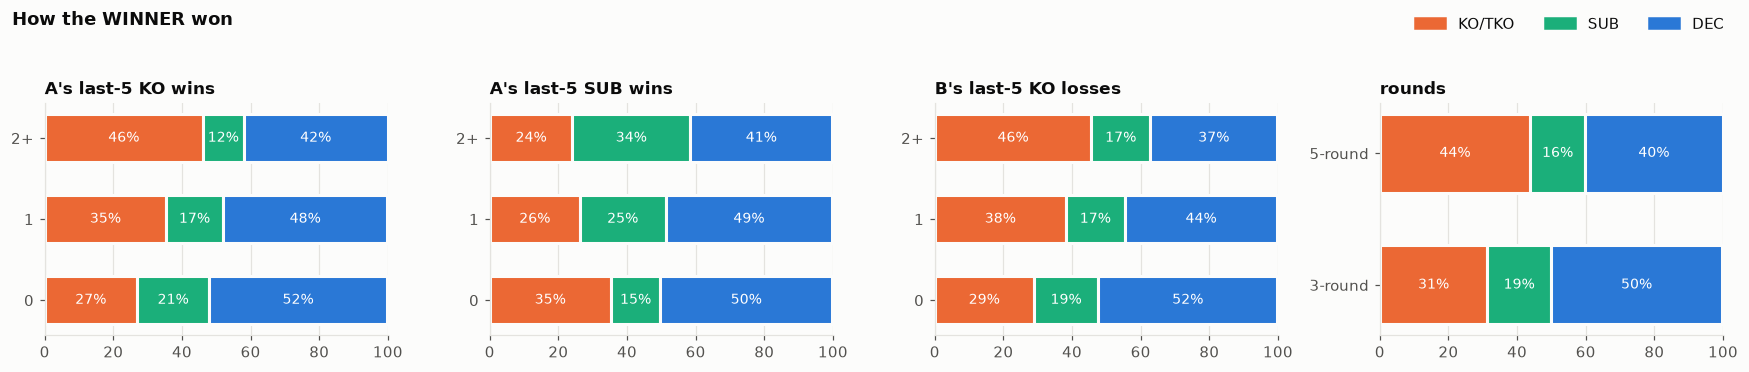

In [6]:
won = A[A.won == 1].copy()
won["A's last-5 KO wins"] = pd.cut(won.r_l5_ko_w, [-1, 0, 1, 99], labels=["0", "1", "2+"])
won["A's last-5 SUB wins"] = pd.cut(won.r_l5_sub_w, [-1, 0, 1, 99], labels=["0", "1", "2+"])
won["B's last-5 KO losses"] = pd.cut(won.b_l5_ko_l, [-1, 0, 1, 99], labels=["0", "1", "2+"])
won["rounds"] = np.where(won.five_rounds == 1, "5-round", "3-round")

panels = ["A's last-5 KO wins", "A's last-5 SUB wins", "B's last-5 KO losses", "rounds"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharex=True)
for ax, col in zip(axes, panels):
    mix = pd.crosstab(won[col], won.method_group, normalize="index")[["KO/TKO", "SUB", "DEC"]] * 100
    left = np.zeros(len(mix))
    for m in mix.columns:
        ax.barh(mix.index.astype(str), mix[m], left=left, color=METHOD_COLORS[m], height=0.6, label=m,
                edgecolor="#fcfcfb", linewidth=2)
        for i, (l, v) in enumerate(zip(left, mix[m])):
            if v >= 9:
                ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
        left += mix[m].values
    ax.set_title(col, fontsize=11); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=METHOD_COLORS[m]) for m in ["KO/TKO", "SUB", "DEC"]]
fig.legend(handles, ["KO/TKO", "SUB", "DEC"], ncol=3, loc="upper right", bbox_to_anchor=(0.99, 1.0))
fig.suptitle("How the WINNER won", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

**Reading this:**
- **How you've been winning predicts how you'll win next.** Fighters with 2+ KO wins in their last five win by KO about 46% of the time, against 27% for fighters with none. Submission artists show the same pattern.
- **The loser's lead-up matters too.** When the loser has been stopped by KO twice or more recently, KO finishes jump in the same way. Chins don't come back.
- **Five-round fights end by KO *more* often, not less** (44% vs 31%). Those are main events, with elite strikers and an extra 10 minutes for damage to add up.

### A model for "who and how"
Seven outcomes: Red by KO/TKO, SUB or DEC; Blue by KO/TKO, SUB or DEC; or Other (DQ etc.). Three approaches, tuned on 2021–2023 and scored on 2024+:
1. **Base rates:** always predict the historical mix.
2. **One big multinomial model:** a single logistic regression straight to the 7 outcomes.
3. **Two-step model:** P(who wins) from the win model × P(method | that fighter wins).
   The second part is the winner's own career KO/SUB/DEC mix, shrunk toward the average, optionally × the loser's recent ways of losing.

Log loss for 7 outcomes: lower is better. Base rates are the bar to clear.

In [7]:
VAL = pd.Timestamp("2021-01-01")
tr, va = t[t.date < VAL], t[(t.date >= VAL) & (t.date < M.SPLIT)]
trall, te = t[t.date < M.SPLIT], t[t.date >= M.SPLIT]
L = sorted(M.OUTCOMES)
ll7 = lambda y, P: log_loss(y, P[L].values, labels=L)

WIN_COLS = M.diffs(MIN_FEATURES + HIST_FEATURES + F.OPP_FEATURES) + M.FLAGS + ["red_corner"]
SIDE = ["ko_wins", "sub_wins", "dec_wins", "been_finished", "l5_ko_w", "l5_sub_w", "l5_dec_w",
        "l5_ko_l", "l5_sub_l", "l5_dec_l", "kd_per15", "sub_per15", "td_per15", "slpm", "sapm", "l5_avg_min", "n_fights"]
MULTI_COLS = WIN_COLS[:-1] + ["r_" + c for c in SIDE] + ["b_" + c for c in SIDE] + ["weight_lbs", "women", "five_rounds", "red_corner"]

def aug7(df):
    a = df.assign(red_corner=1); b = swap_corners(df).assign(red_corner=-1)
    b["outcome"] = M.swap_outcome(df.outcome).values
    return pd.concat([a, b], ignore_index=True)

prior = tr[tr.method_group.isin(M.METHODS)].method_group.value_counts(normalize=True).to_dict()
p_va = M.predict(M.fit(M.logistic(), tr, WIN_COLS), va, WIN_COLS)
grid = pd.DataFrame([{"k": k, "loser_weight": lw, "val_log_loss": ll7(va.outcome, M.method_probs(va, p_va, prior, k, lw))}
                     for k in [3, 6, 10, 15, 25, 40] for lw in [0, 0.5, 1]])
best = grid.loc[grid.val_log_loss.idxmin()]
a_tr = aug7(tr)
multi = {C: ll7(va.outcome, pd.DataFrame(M.logistic(C).fit(a_tr[MULTI_COLS], a_tr.outcome)
                                          .predict_proba(va.assign(red_corner=1)[MULTI_COLS]), columns=sorted(a_tr.outcome.unique())))
         for C in [0.005, 0.01, 0.02, 0.05]}
best_C = min(multi, key=multi.get)
print("two-step best on validation:", best.to_dict()); print("multinomial C on validation:", {k: round(v, 4) for k, v in multi.items()})
grid.pivot(index="k", columns="loser_weight", values="val_log_loss").round(4)

two-step best on validation: {'k': 6.0, 'loser_weight': 0.0, 'val_log_loss': 1.648732330656398}
multinomial C on validation: {0.005: 1.6434, 0.01: 1.6469, 0.02: 1.6502, 0.05: 1.6533}


loser_weight,0.0,0.5,1.0
k,,,
3,1.6591,1.6631,1.7183
6,1.6487,1.6537,1.6963
10,1.6501,1.6572,1.6971
15,1.6543,1.6633,1.7031
25,1.6611,1.6722,1.7129
40,1.6674,1.6800,1.7218


,log loss (7 outcomes),exact outcome right,method right (ignoring who)
base rates,1.726,0.222,0.487
one multinomial model,1.615,0.334,0.512
two-step: winner × method mix,1.619,0.315,0.490


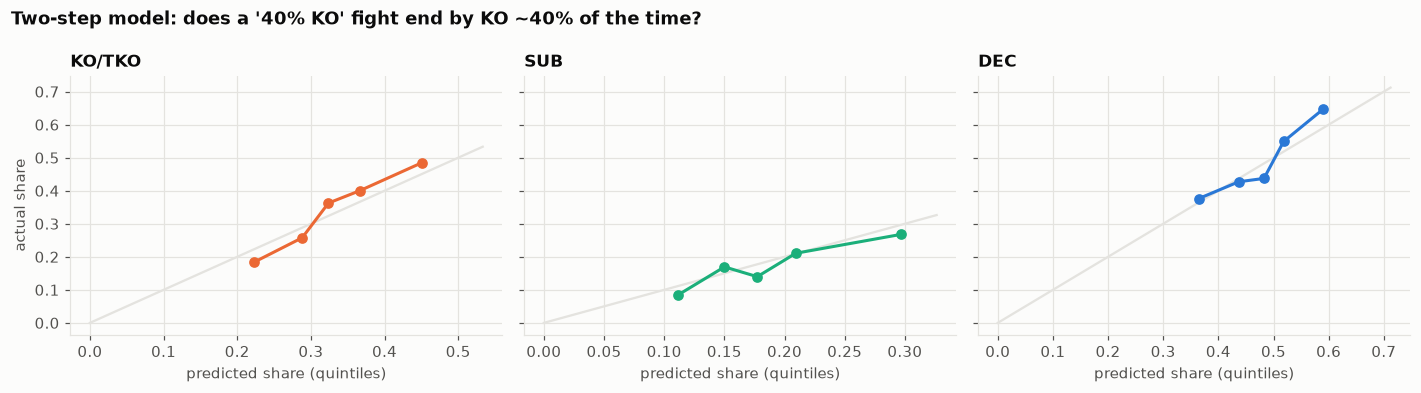

In [8]:
a_all = aug7(trall)
base_rates = a_all.outcome.value_counts(normalize=True)
P_base = pd.DataFrame(np.tile(base_rates.reindex(L).values, (len(te), 1)), columns=L)
mm = M.logistic(best_C).fit(a_all[MULTI_COLS], a_all.outcome)
P_multi = pd.DataFrame(mm.predict_proba(te.assign(red_corner=1)[MULTI_COLS]), columns=mm.classes_)
p_te = M.predict(M.fit(M.logistic(), trall, WIN_COLS), te, WIN_COLS)
prior_all = trall[trall.method_group.isin(M.METHODS)].method_group.value_counts(normalize=True).to_dict()
P_two = M.method_probs(te, p_te, prior_all, best.k, best.loser_weight)

meth = lambda o: pd.Series(o).str.split().str[-1].values
res7 = {}
for name, P in [("base rates", P_base), ("one multinomial model", P_multi), ("two-step: winner × method mix", P_two)]:
    pick = P[L].idxmax(axis=1).values
    res7[name] = {"log loss (7 outcomes)": ll7(te.outcome, P), "exact outcome right": (pick == te.outcome.values).mean(),
                  "method right (ignoring who)": (meth(pick) == meth(te.outcome.values)).mean()}
display(pd.DataFrame(res7).T.round(3))

# method calibration of the two-step model: predicted vs actual share of KO / SUB / DEC
pm = pd.DataFrame({m: P_two[f"Red {m}"] + P_two[f"Blue {m}"] for m in M.METHODS})
act = pd.get_dummies(te.method_group).reindex(columns=M.METHODS, fill_value=0).astype(float)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, m in zip(axes, M.METHODS):
    q = pd.qcut(pm[m], 5, labels=False, duplicates="drop")
    cal = pd.DataFrame({"pred": pm[m].values, "obs": act[m].values}).groupby(q.values).mean()
    hi = max(cal.max().max(), 0.1) * 1.1
    ax.plot([0, hi], [0, hi], color=GRID, lw=1.5)
    ax.plot(cal.pred, cal.obs, marker="o", color=METHOD_COLORS[m])
    ax.set_title(f"{m}", fontsize=11); ax.set_xlabel("predicted share (quintiles)")
axes[0].set_ylabel("actual share")
fig.suptitle("Two-step model: does a '40% KO' fight end by KO ~40% of the time?", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Reading this:**
- Both models beat the base rates clearly. They pick the exact outcome (who *and* how) about **33%** of the time, against 22% for base rates.
- On method alone (ignoring who), they barely beat "always pick decision" (49%). Method is much harder to predict than the winner.
- The single multinomial model and the two-step model end up almost tied. The two-step model is simpler, and a simulator can reuse it directly: pick a winner, then a method.
- Calibration is good. When the model says 45% KO, about 45–50% of those fights end by KO.
- On validation, the loser's recent losses didn't help (`loser_weight = 0` was best). Last-5 loss counts are too noisy; the effect in the chart above is real but small.

## 4 · Test it properly: does each layer add anything?
The notebook-04 history model is the starting point. We add one layer at a time, training on 2010-03 → 2023 and testing on 2024 → 2026-10.
The last column is a **bootstrap 95% interval** for the change in log loss from the row above. If it contains 0, the gain could be luck.

*Note:* the baseline row is 64.2% here vs 64.3% in notebook 04. That's one fight out of 1,475, from numerical differences between library versions (`.venv` vs the Anaconda env); log loss is identical.

,accuracy,log_loss,roc_auc,Δ log loss,95% interval
model,,,,,
history baseline (nb 04),0.6420,0.6401,0.6844,NaN,
+ recent form (layer 1),0.6393,0.6390,0.6853,-0.0011,"[-0.0033, +0.0011]"
+ who they beat (layer 2),0.6427,0.6370,0.6901,-0.0020,"[-0.0059, +0.0022]"
+ OWP / OOWP (layer 3),0.6461,0.6344,0.6956,-0.0026,"[-0.0047, -0.0007]"
+ common opponents (layer 4),0.6447,0.6354,0.6930,0.0010,"[-0.0005, +0.0025]"
+ style + physical,0.6454,0.6364,0.6915,0.0010,"[-0.0012, +0.0031]"
+ Elo,0.6420,0.6357,0.6924,-0.0007,"[-0.0022, +0.0008]"


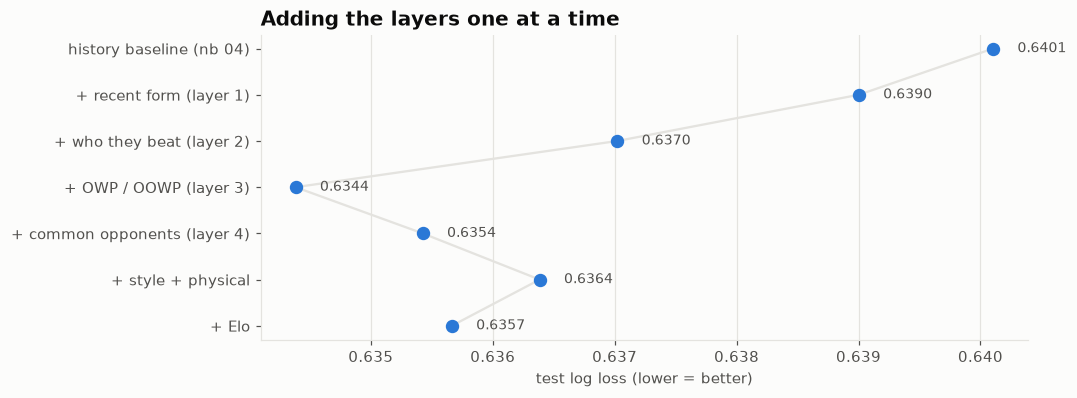

In [9]:
BASE = M.diffs(MIN_FEATURES + HIST_FEATURES) + M.FLAGS + ["red_corner"]
BLOCKS = {"recent form (layer 1)": F.FORM_FEATURES, "who they beat (layer 2)": F.OPP_FEATURES,
          "OWP / OOWP (layer 3)": F.SOS_FEATURES, "common opponents (layer 4)": F.COMMON_FEATURES,
          "style + physical": F.STYLE_FEATURES, "Elo": ["elo_pre"]}
rows, preds, cols, prev = [], {}, list(BASE), None
for name, block in [("history baseline (nb 04)", [])] + list(BLOCKS.items()):
    cols = cols + M.diffs(block)
    p = M.predict(M.fit(M.logistic(), trall, cols), te, cols)
    d, lo, hi = M.bootstrap_delta(te.red_win, p, prev) if prev is not None else (np.nan,) * 3
    rows.append({"model": ("+ " if block else "") + name, **M.scores(te.red_win, p), "Δ log loss": d, "95% interval": f"[{lo:+.4f}, {hi:+.4f}]" if block else ""})
    preds[name], prev = p, p
abl = pd.DataFrame(rows).set_index("model")
display(abl.round(4))

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(abl))[::-1]
ax.plot(abl.log_loss, y, color=GRID, lw=1.5, zorder=1)
ax.scatter(abl.log_loss, y, s=60, color=SERIES[0], zorder=2)
for yi, v in zip(y, abl.log_loss):
    ax.text(v + 0.0002, yi, f"{v:.4f}", va="center", color=INK_2, fontsize=9)
ax.set_yticks(y, abl.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("test log loss (lower = better)"); ax.set_title("Adding the layers one at a time")
plt.show()

### Two upgrades: shrinkage, and choosing blocks without peeking
**Shrinkage (partial pooling).** A fighter with 2 UFC fights might show 9 strikes absorbed per minute, which is mostly noise.
Notebook 04 clipped extreme values. A better fix pulls each career rate toward the division average in proportion to the sample size:
`shrunk = (n·x + k·μ) / (n + k)`. With *k* = 5, a 1-fight fighter is about 83% division average, and a 20-fight veteran about 80% themselves. *k* is chosen on 2021–2023, never on the test years.

**Honest block selection.** Picking blocks by test score is quietly cheating: with enough tries something always "helps".
So blocks are added greedily based on the **2021–2023 validation** score, and the test set is used once at the end.

In [10]:
tr_va = []
for k in [None, 1, 2, 3, 5, 8, 12]:
    tk, _ = M.load_model_table(shrink_k=k) if k else (t, None)
    a, v = tk[tk.date < VAL], tk[(tk.date >= VAL) & (tk.date < M.SPLIT)]
    p = M.predict(M.fit(M.logistic(), a, BASE), v, BASE)
    tr_va.append({"k": k or 0, "validation log loss": log_loss(v.red_win, p)})
kv = pd.DataFrame(tr_va).set_index("k")
K = int(kv["validation log loss"].round(4).idxmin())
display(kv.round(4).T)
print(f"chosen k = {K}")

ts, _ = M.load_model_table(shrink_k=K)
s_tr, s_va, s_trall, s_te = ts[ts.date < VAL], ts[(ts.date >= VAL) & (ts.date < M.SPLIT)], ts[ts.date < M.SPLIT], ts[ts.date >= M.SPLIT]
chosen, cols = [], list(BASE)
best_v = log_loss(s_va.red_win, M.predict(M.fit(M.logistic(), s_tr, cols), s_va, cols))
log = [{"step": "shrunk baseline", "validation log loss": best_v}]
while True:
    cand = {b: log_loss(s_va.red_win, M.predict(M.fit(M.logistic(), s_tr, cols + M.diffs(v)), s_va, cols + M.diffs(v)))
            for b, v in BLOCKS.items() if b not in chosen}
    if not cand: break
    b = min(cand, key=cand.get)
    log.append({"step": f"best next: {b}", "validation log loss": cand[b]})
    if cand[b] < best_v - 0.0005:
        chosen.append(b); cols += M.diffs(BLOCKS[b]); best_v = cand[b]
    else:
        log[-1]["step"] += "  (gain < 0.0005, stop)"; break
display(pd.DataFrame(log).set_index("step").round(4))
FINAL_COLS = cols
print("blocks kept:", chosen)

k,0,1,2,3,5,8,12
validation log loss,0.6475,0.6467,0.6463,0.6461,0.6459,0.6459,0.6461


chosen k = 5


,validation log loss
step,
shrunk baseline,0.6459
best next: who they beat (layer 2),0.6440
"best next: common opponents (layer 4) (gain < 0.0005, stop)",0.6436


blocks kept: ['who they beat (layer 2)']


In [11]:
final = {}
for name, data, c, mdl in [
    ("history baseline (nb 04)", (trall, te), BASE, M.logistic()),
    (f"history, shrunk (k={K})", (s_trall, s_te), BASE, M.logistic()),
    ("shrunk + validation-chosen blocks", (s_trall, s_te), FINAL_COLS, M.logistic()),
    ("shrunk + ALL blocks (not chosen; for reference)", (s_trall, s_te), BASE + M.diffs(sum(BLOCKS.values(), [])), M.logistic()),
    ("gradient boosting, ALL blocks", (s_trall, s_te), BASE + M.diffs(sum(BLOCKS.values(), [])), M.boosted()),
    ("Elo only", (trall, te), ["elo_pre_diff", "red_corner"], M.logistic()),
]:
    a, b = data
    final[name] = M.scores(b.red_win, M.predict(M.fit(mdl, a, c), b, c))
FINAL = pd.DataFrame(final).T
FINAL.round(3)

,accuracy,log_loss,roc_auc
history baseline (nb 04),0.642,0.640,0.684
"history, shrunk (k=5)",0.642,0.636,0.690
shrunk + validation-chosen blocks,0.639,0.635,0.694
shrunk + ALL blocks (not chosen; for reference),0.648,0.633,0.696
"gradient boosting, ALL blocks",0.641,0.638,0.688
Elo only,0.559,0.682,0.578


**Reading the ablation:**
- **Strength of schedule (OWP/OOWP)** is the only layer whose gain is clearly bigger than noise: its interval excludes zero. "Who did your opponents beat" carries real signal.
- Recent form and "who they beat" each help a little, but their intervals include zero.
- Common opponents, style/physical, and Elo add nothing once everything else is in. Most of what they know is already in the other features.

**Shrinkage is the biggest single win.** Pulling noisy career rates toward the division average (k = 5) improves log loss as much as all the new layers combined, without adding one feature.

**On honest selection:** validation (2021–23) picked "who they beat", not OWP, and the chosen model scores 0.635 on test. Including every block happens to score 0.633 on test, but we only know that *by looking at the test set*.
That gap is the price of honesty, and it's small. Gradient boosting doesn't beat logistic regression here: there's too little data for its extra flexibility to pay off.

## Takeaways
1. **Your idea holds up, in a specific form.**
   - Raw lead-ups predict the next result: 5-of-5 fighters win about 62%.
   - What matters is the *gap* between both fighters' lead-ups, and **who they beat**: a win over a fighter on a hot streak cancels out the other fighter's streak.
2. **Strength of schedule is the layer that survives a fair test.** Opponents' records, and their opponents' records, add real information beyond career stats.
3. **"How" is predictable too.**
   - Fighters keep winning the way they've been winning, and 5-round fights end by KO more often.
   - A two-step model (who wins × how that fighter wins) gets the exact outcome right about 33% of the time vs 22% for base rates, and is well calibrated. That's exactly the shape a fight simulator needs.
4. **Fight chains ("MMA math") are mostly noise**: right 55–57% of the time, and they add nothing to the model.
5. **Shrinkage beats new features.** Statistically smarter handling of small samples gave the single largest improvement.
6. Every gain here is small (log loss 0.640 → 0.635, AUC 0.684 → 0.694). Fights are close to the limit of what records can tell us. **Notebook 08** looks at *why*: what drives each prediction, how much fighters with short records hurt, and which fights the model gets wrong.